In [1]:
# Use this script to produce plots for a specified lat-lon point
# Uses hourly data
# This script uses output from wbgt_BARRA_testing.ipynb

In [2]:
# Import modules
import numpy as np
import netCDF4 as nc
import xarray as xr
import sys, os
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
import glob

EU = os.path.expanduser

sys.path.append(EU("/home/565/cdr565/heat/others_code/atmos/"))
from atmos import moisture


In [3]:
def print_run_time(start_timer):
    end_timer = time_pack.perf_counter()
    print('')
    print('Code run time: ' + str(np.round((end_timer - start_timer) / 60,2)) + ' minutes')
    

In [4]:
# User inputs
set_month = '01' # month (e.g. '01')
daily_freq = 'max' # Daily max or min data

specify_test = 'above_curve_magnitude_t'
specify_point = 0 # 0 to 9

examine_radiation_rsds = 'yes'
examine_radiation = 'yes' # Includes all four radiation terms
examine_wind = 'yes'
examine_windmax = 'yes'
examine_humidity = 'yes'
examine_pressure = 'yes'

dir_out = '/home/565/cdr565/heat/figures/'


In [5]:
start_year = 1979
end_year = 2024


In [6]:

dir_dir = '/home/565/cdr565/heat/figures/'

if specify_test == 'above_curve_magnitude_t':
    text_fname_in = 'top10-magnitude-t_' + set_month

text_file_name = text_fname_in + '.txt'

with open(dir_dir + text_file_name, "r") as text_file:
    data = text_file.readlines()

str_part = data[specify_point]
lat_lat = float(str_part[0:str_part.find(',')])
str_part = str_part[str_part.find(',')+1:]
lon_lon = float(str_part[0:str_part.find(',')])
str_part = str_part[str_part.find(',')+1:]
try:
    num_test_outliers = float(str_part[0:-1])
except:
    num_test_outliers = float(str_part[0:str_part.find(',')])
    str_part = str_part[str_part.find(',')+1:]
    value_test_outliers = float(str_part[0:-1])


In [7]:
# Get filenames

# Hourly data
data_location_wbgt = '/scratch/tp28/wbgt/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/wbgt/v20250901/'

wbgt_label = 'WBGT (\N{degree sign}C)'

if (set_month == 'all') and ('tp28' in data_location_wbgt):
    fnames = glob.glob('{}wbgt*BARRA*.nc'.format(data_location_wbgt))
elif 'tp28' in data_location_wbgt:
    fnames = glob.glob('{}wbgt*BARRA*{}.nc'.format(data_location_wbgt,set_month))
fnames.sort()

print(fnames[0])
print(fnames[-1])

assert len(fnames) == end_year - start_year + 1


/scratch/tp28/wbgt/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/wbgt/v20250901/wbgt_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/scratch/tp28/wbgt/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/wbgt/v20250901/wbgt_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [8]:
# The following functions allow only a specific part of the data to be read in - this is done to save time

from functools import partial
def _preprocess(x, lon_bnds, lat_bnds):
    return x.sel(lon=slice(*lon_bnds), lat=slice(*lat_bnds))

def get_partial_func(lon_lon, lat_lat):
    lon_bnds, lat_bnds = (lon_lon, lon_lon), (lat_lat, lat_lat)
    partial_func = partial(_preprocess, lon_bnds=lon_bnds, lat_bnds=lat_bnds)
    return partial_func


In [9]:
ds = xr.open_mfdataset(fnames,parallel=True,preprocess=get_partial_func(lon_lon, lat_lat))

# Check if wrong number of entries
if set_month in ['01', '03', '05', '07', '08', '10', '12']:
    set_days = (end_year - start_year + 1) * 24 * 31
elif set_month in ['04', '06', '09', '11']:
    set_days = (end_year - start_year + 1) * 24 * 30
elif set_month == '02':
    assert start_year == 1979
    assert end_year == 2024
    set_days = (2024 - 1979 + 1 - 11) * 24 * 28 + (11 * 24 * 29)

assert len(ds.time) == set_days
# If this fails, try running again


In [10]:
# T data
# long_name = Near-Surface Air Temperature
# standard_name = air_temperature
# units = K

data_location_T = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/tas/latest/'

fnames_T = glob.glob('{}tas*{}.nc'.format(data_location_T,set_month))
fnames_T.sort()

t_var_name = 'tas'
t_label = '$\it{T}$ (\N{degree sign}C)'

for i in np.arange(len(fnames_T)):
    if ('2025' + set_month + '.nc' in fnames_T[i]) and (i+1 == len(fnames_T)):
        fnames_T = fnames_T[0:-1]
        
assert len(fnames_T) == end_year - start_year + 1

print(fnames_T[0])
print(fnames_T[-1])


/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/tas/latest/tas_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/tas/latest/tas_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [11]:
ds_t = xr.open_mfdataset(fnames_T,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
assert len(ds.time) == len(ds_t.time)


In [12]:
if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
    # rsds data (surface downwelling longwave radiation)
    # long_name = Surface Downwelling Shortwave Radiation
    # standard_name = surface_downwelling_shortwave_flux_in_air
    # units = W m-2
    
    rsds_var_name = 'rsds'
    rsds_label = 'Radiation SW down (W m$^{-2}$)'
    
    # Daily data
    data_location_rsds = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/' + rsds_var_name + '/latest/'
    
    fnames_rsds = glob.glob('{}{}*{}.nc'.format(data_location_rsds,rsds_var_name,set_month))
    fnames_rsds.sort()
    
    for i in np.arange(len(fnames_rsds)):
        if ('2025' + set_month + '.nc' in fnames_rsds[i]) and (i+1 == len(fnames_rsds)):
            fnames_rsds = fnames_rsds[0:-1]
    assert len(fnames_rsds) == end_year - start_year + 1
    
    print(fnames_rsds[0])
    print(fnames_rsds[-1])
    

/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/rsds/latest/rsds_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/rsds/latest/rsds_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [13]:
if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
    ds_rsds = xr.open_mfdataset(fnames_rsds,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
    assert len(ds.time) == len(ds_rsds.time)
    

In [14]:
if examine_radiation == 'yes':
    # rlds data (surface downwelling longwave radiation)
    # long_name = Surface Downwelling Longwave Radiation
    # standard_name = surface_downwelling_longwave_flux_in_air
    # units = W m-2
    
    rlds_var_name = 'rlds'
    rlds_label = 'Radiation LW down (W m$^{-2}$)'
    
    # Daily data
    data_location_rlds = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/' + rlds_var_name + '/latest/'
    
    fnames_rlds = glob.glob('{}{}*{}.nc'.format(data_location_rlds,rlds_var_name,set_month))
    fnames_rlds.sort()
    
    for i in np.arange(len(fnames_rlds)):
        if ('2025' + set_month + '.nc' in fnames_rlds[i]) and (i+1 == len(fnames_rlds)):
            fnames_rlds = fnames_rlds[0:-1]
    assert len(fnames_rlds) == end_year - start_year + 1
    
    print(fnames_rlds[0])
    print(fnames_rlds[-1])
    

/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/rlds/latest/rlds_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/rlds/latest/rlds_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [15]:
if examine_radiation == 'yes':
    ds_rlds = xr.open_mfdataset(fnames_rlds,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
    assert len(ds.time) == len(ds_rlds.time)
    

In [16]:
if examine_radiation == 'yes':
    # rsus data (surface upwelling shortwave radiation)
    # long_name = Surface Upwelling Shortwave Radiation
    # standard_name = surface_upwelling_shortwave_flux_in_air
    # units = W m-2
    
    # Daily data
    data_location_rsus = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/rsus/latest/'
    
    fnames_rsus = glob.glob('{}rsus*{}.nc'.format(data_location_rsus,set_month))
    fnames_rsus.sort()

    for i in np.arange(len(fnames_rsus)):
        if ('2025' + set_month + '.nc' in fnames_rsus[i]) and (i+1 == len(fnames_rsus)):
            fnames_rsus = fnames_rsus[0:-1]
    assert len(fnames_rsus) == end_year - start_year + 1
    
    rsus_var_name = 'rsus'
    rsus_label = 'Radiation SW up (W m$^{-2}$)'

    print(fnames_rsus[0])
    print(fnames_rsus[-1])
    

/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/rsus/latest/rsus_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/rsus/latest/rsus_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [17]:
if examine_radiation == 'yes':
    ds_rsus = xr.open_mfdataset(fnames_rsus,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
    assert len(ds.time) == len(ds_rsus.time)
    

In [18]:
if examine_radiation == 'yes':
    # rlus data (surface downwelling longwave radiation)
    # long_name = Surface Upwelling longwave Radiation
    # standard_name = surface_upwelling_longwave_flux_in_air
    # units = W m-2
    
    rlus_var_name = 'rlus'
    rlus_label = 'Radiation LW up (W m$^{-2}$)'
    
    # Daily data
    data_location_rlus = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/' + rlus_var_name + '/latest/'
    
    fnames_rlus = glob.glob('{}{}*{}.nc'.format(data_location_rlus,rlus_var_name,set_month))
    fnames_rlus.sort()
    
    for i in np.arange(len(fnames_rlus)):
        if ('2025' + set_month + '.nc' in fnames_rlus[i]) and (i+1 == len(fnames_rlus)):
            fnames_rlus = fnames_rlus[0:-1]
    assert len(fnames_rlus) == end_year - start_year + 1
    
    print(fnames_rlus[0])
    print(fnames_rlus[-1])
    

/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/rlus/latest/rlus_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/rlus/latest/rlus_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [19]:
if examine_radiation == 'yes':
    ds_rlus = xr.open_mfdataset(fnames_rlus,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
    assert len(ds.time) == len(ds_rlus.time)
    

In [20]:
if examine_humidity == 'yes':
    # huss data (specific humidity)
    # long_name = Near-Surface Specific Humidity
    # standard_name = specific_humidity
    # units = 1
    
    # Daily data
    huss_var_name = 'huss'
    huss_label = 'Specific humidity (kg kg$^{-1}$)'
    
    data_location_huss = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/' + huss_var_name + '/latest/'
    
    fnames_huss = glob.glob('{}{}*{}.nc'.format(data_location_huss,huss_var_name,set_month))
    fnames_huss.sort()
    
    for i in np.arange(len(fnames_huss)):
        if ('2025' + set_month + '.nc' in fnames_huss[i]) and (i+1 == len(fnames_huss)):
            fnames_huss = fnames_huss[0:-1]
    assert len(fnames_huss) == end_year - start_year + 1
    
    print(fnames_huss[0])
    print(fnames_huss[-1])


/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/huss/latest/huss_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/huss/latest/huss_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [21]:
if examine_humidity == 'yes':
    ds_huss = xr.open_mfdataset(fnames_huss,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
    assert len(ds.time) == len(ds_huss.time)


In [22]:
if examine_humidity == 'yes':
    # hurs data (relative humidity)
    # long_name = Near-Surface Relative Humidity
    # standard_name = relative_humidity
    # units = %
    
    # Daily data
    hurs_var_name = 'hurs'
    hurs_label = 'Relative humidity (%)'
    
    data_location_hurs = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/' + hurs_var_name + '/latest/'
    
    fnames_hurs = glob.glob('{}{}*{}.nc'.format(data_location_hurs,hurs_var_name,set_month))
    fnames_hurs.sort()
    
    for i in np.arange(len(fnames_hurs)):
        if ('2025' + set_month + '.nc' in fnames_hurs[i]) and (i+1 == len(fnames_hurs)):
            fnames_hurs = fnames_hurs[0:-1]
    assert len(fnames_hurs) == end_year - start_year + 1
    
    print(fnames_hurs[0])
    print(fnames_hurs[-1])


/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/hurs/latest/hurs_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/hurs/latest/hurs_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [23]:
if examine_humidity == 'yes':
    ds_hurs = xr.open_mfdataset(fnames_hurs,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
    assert len(ds.time) == len(ds_hurs.time)


In [24]:
if examine_pressure == 'yes':
    # pressure data
    # long_name = Surface Air Pressure
    # standard_name = surface_air_pressure
    # units = Pa
    
    # Daily data
    data_location_p = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/ps/latest/'
    
    fnames_p = glob.glob('{}ps*{}.nc'.format(data_location_p,set_month))
    fnames_p.sort()
    
    for i in np.arange(len(fnames_p)):
        if ('2025' + set_month + '.nc' in fnames_p[i]) and (i+1 == len(fnames_p)):
            fnames_p = fnames_p[0:-1]
    assert len(fnames_p) == end_year - start_year + 1
    
    p_var_name = 'ps'
    p_label = 'Surface pressure (Pa)'
    
    print(fnames_p[0])
    print(fnames_p[-1])
    

/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/ps/latest/ps_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/ps/latest/ps_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [25]:
if examine_pressure == 'yes':
    ds_p = xr.open_mfdataset(fnames_p,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
    assert len(ds.time) == len(ds_p.time)


In [26]:
if examine_wind == 'yes':
    # sfcWind
    # long_name = Near-Surface Wind Speed
    # standard_name = wind_speed
    # units = m s-1

    # Daily data
    wind_var_name = 'sfcWind'
    wind_label = 'Wind speed (m s$^{-1}$)'
    
    data_location_wind = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/' + wind_var_name + '/latest/'
    
    fnames_wind = glob.glob('{}{}*{}.nc'.format(data_location_wind,wind_var_name,set_month))
    fnames_wind.sort()
    
    for i in np.arange(len(fnames_wind)):
        if ('2025' + set_month + '.nc' in fnames_wind[i]) and (i+1 == len(fnames_wind)):
            fnames_wind = fnames_wind[0:-1]
    assert len(fnames_wind) == end_year - start_year + 1
    
    print(fnames_wind[0])
    print(fnames_wind[-1])
    

/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/sfcWind/latest/sfcWind_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/sfcWind/latest/sfcWind_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [27]:
if examine_wind == 'yes':
    ds_wind = xr.open_mfdataset(fnames_wind,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
    assert len(ds.time) == len(ds_wind.time)


In [28]:
if examine_windmax == 'yes':
    # sfcWindmax
    # long_name = Hourly Maximum Near-Surface Wind Speed
    # standard_name = wind_speed
    # units = m s-1

    # Daily data
    windmax_var_name = 'sfcWindmax'
    windmax_label = 'Hourly maximum wind speed (m s$^{-1}$)'
    
    data_location_windmax = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/' + windmax_var_name + '/latest/'
    
    fnames_windmax = glob.glob('{}{}*{}.nc'.format(data_location_windmax,windmax_var_name,set_month))
    fnames_windmax.sort()
    
    for i in np.arange(len(fnames_windmax)):
        if ('2025' + set_month + '.nc' in fnames_windmax[i]) and (i+1 == len(fnames_windmax)):
            fnames_windmax = fnames_windmax[0:-1]
    assert len(fnames_windmax) == end_year - start_year + 1
    
    print(fnames_windmax[0])
    print(fnames_windmax[-1])
    

/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/sfcWindmax/latest/sfcWindmax_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_197901-197901.nc
/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/1hr/sfcWindmax/latest/sfcWindmax_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_1hr_202401-202401.nc


In [29]:
if examine_windmax == 'yes':
    ds_windmax = xr.open_mfdataset(fnames_windmax,parallel=True,coords='minimal',compat='no_conflicts',preprocess=get_partial_func(lon_lon, lat_lat))
    assert len(ds.time) == len(ds_windmax.time)

In [30]:
t_computed = ds_t[t_var_name][:,0,0].compute() - 273.15


In [31]:
wbgt_computed = ds['wbgt'][:,0,0].compute() - 273.15


In [32]:
if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
    rsds_computed = ds_rsds[rsds_var_name][:,0,0].compute()
if examine_radiation == 'yes':
    rlds_computed = ds_rlds[rlds_var_name][:,0,0].compute()
    rsus_computed = ds_rsus[rsus_var_name][:,0,0].compute()
    rlus_computed = ds_rlus[rlus_var_name][:,0,0].compute()


In [33]:
if examine_humidity == 'yes':
    huss_computed = ds_huss[huss_var_name][:,0,0].compute()
    hurs_computed = ds_hurs[hurs_var_name][:,0,0].compute()


In [34]:
if examine_pressure == 'yes':
    p_computed = ds_p[p_var_name][:,0,0].compute()


In [35]:
if examine_wind == 'yes':
    wind_computed = ds_wind[wind_var_name][:,0,0].compute()
if examine_windmax == 'yes':
    windmax_computed = ds_windmax[windmax_var_name][:,0,0].compute()
    

In [36]:
wbgt_t_diff = wbgt_computed - t_computed


In [37]:
if examine_humidity == 'yes':
    vap_pres = moisture.vapour_pressure_from_relative_humidity(t_computed + 273.15, hurs_computed / 100.) / 100.
    
    swbgt = 0.567 * t_computed + 0.393 * vap_pres + 3.94
    
    swbgt_wbgt_diff = swbgt - wbgt_computed


In [38]:
if examine_humidity == 'yes':
    np.nanmin(wbgt_computed - swbgt) # -6.70, 12.44

In [39]:
# Create masks

# light breeze = 1.6–3.3 m/s
# https://www.rmets.org/metmatters/beaufort-wind-scale
# https://en.wikipedia.org/wiki/Beaufort_scale

light_wind_min = 1.6
light_wind_max = 3.3

set_buffer = 0

mod_rad_min = 400.
    
if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
    night_mask = np.ones(len(rsds_computed))
    night_mask[np.where(rsds_computed == 0.)] = np.nan
    
    low_rad_mask = np.ones(len(rsds_computed))
    low_rad_mask[np.where(rsds_computed < mod_rad_min)] = np.nan

    
if examine_wind == 'yes':
    wind_mask = np.ones(len(wind_computed))
    wind_mask[np.where(wind_computed < light_wind_min)] = np.nan
    wind_mask[np.where(wind_computed > light_wind_max)] = np.nan
    
    high_wind_mask = np.ones(len(wind_computed))
    high_wind_mask[np.where(wind_computed > light_wind_max)] = np.nan
    
    low_wind_mask = np.ones(len(wind_computed))
    low_wind_mask[np.where(wind_computed < light_wind_min)] = np.nan
    
    wind_gre1_mask = np.ones(len(wind_computed))
    wind_gre1_mask[np.where(wind_computed >= 1.)] = np.nan
    
    wind_greep5_mask = np.ones(len(wind_computed))
    wind_greep5_mask[np.where(wind_computed >= 0.5)] = np.nan


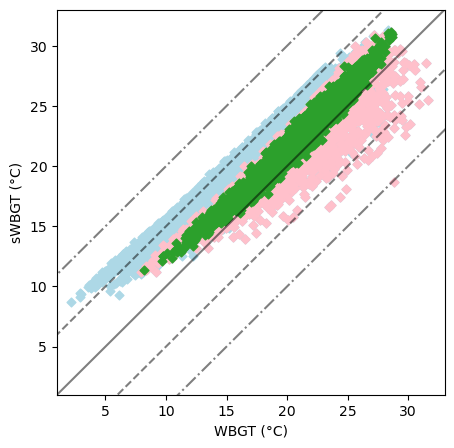

In [40]:
set_msize = 20
set_marker_shape = 'D'

low_rad_colour = 'lightblue'
not_light_wind_colour = 'pink'
set_main_colour = 'mediumorchid'
fourth_colour = 'tab:green'

if examine_humidity == 'yes':

    fig, ax = plt.subplots(1, 1, figsize=(5,5))

    plt.scatter(wbgt_computed,swbgt,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
    plt.scatter(wbgt_computed*low_rad_mask,swbgt,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
    plt.scatter(wbgt_computed*low_rad_mask*high_wind_mask*low_wind_mask,swbgt,s=set_msize,marker=set_marker_shape,c='tab:green')

    set_max = np.nanmax([wbgt_computed,swbgt]) + 2
    set_min = np.nanmin([wbgt_computed,swbgt]) - 2
    
    plt.plot([set_min,set_max],[set_min,set_max],'k', alpha=0.5)
    plt.plot([set_min,set_max],[set_min+5,set_max+5],'k',linestyle='--', alpha=0.5)
    plt.plot([set_min,set_max],[set_min-5,set_max-5],'k',linestyle='--', alpha=0.5)
    plt.plot([set_min,set_max],[set_min+10,set_max+10],'k',linestyle='-.', alpha=0.5)
    plt.plot([set_min,set_max],[set_min-10,set_max-10],'k',linestyle='-.', alpha=0.5)

    set_axes_max = np.floor(set_max)
    set_axes_min = np.ceil(set_min)
    plt.xlim([set_axes_min,set_axes_max])
    plt.ylim([set_axes_min,set_axes_max])

    plt.xlabel('WBGT (\N{degree sign}C)')
    plt.ylabel('sWBGT (\N{degree sign}C)')

    ax.xaxis.set_major_locator(MultipleLocator(5)) # Major ticks
    ax.yaxis.set_major_locator(MultipleLocator(5)) # Major ticks


In [41]:
####################################################################################################
# Remove nans from 2-arrays
def remove_nans_2(array_1,array_2):
    array_1[np.where(np.isnan(array_2))] = np.nan
    array_2[np.where(np.isnan(array_1))] = np.nan
    array_1 = array_1[np.where(~np.isnan(array_1))]
    array_2 = array_2[np.where(~np.isnan(array_2))]
    return array_1, array_2

####################################################################################################

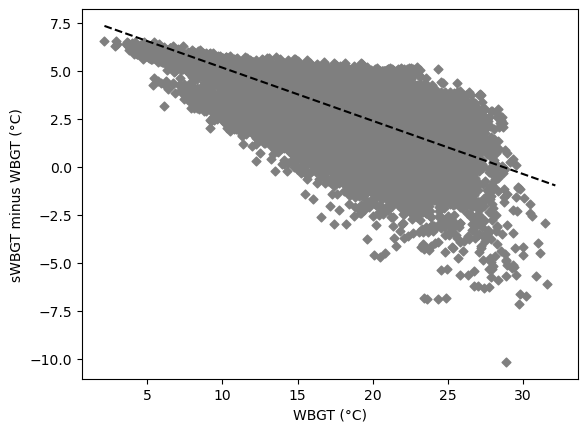

In [42]:
if examine_humidity == 'yes':
    import pylab
        
    wbgt_computed_temp = wbgt_computed.copy()
    swbgt_temp = swbgt - wbgt_computed # *low_rad_mask*wind_mask
    
    plt.scatter(wbgt_computed_temp,swbgt_temp,s=set_msize,marker=set_marker_shape,c='tab:grey')
    
    wbgt_computed_temp, swbgt_temp = remove_nans_2(wbgt_computed_temp, swbgt_temp)
    
    z = np.polyfit(wbgt_computed_temp, swbgt_temp, 1)
    poly = np.poly1d(z)

    wbgt_arange = np.arange(np.nanmin(wbgt_computed),np.nanmax(wbgt_computed)+1)
    pylab.plot(wbgt_arange,poly(wbgt_arange),'k',linestyle='--')
    
    plt.xlabel('WBGT (\N{degree sign}C)')
    plt.ylabel('sWBGT minus WBGT (\N{degree sign}C)')


In [43]:
def wbgt_t_min_limit(t,buffer=5):
    swbgt_t = -0.433 * t + 3.94 - buffer
    return swbgt_t

def wbgt_t_max_limit(t,buffer=5):
    swbgt_t = 1.916 * 10**(-6) * (t**4) + 9.481 * 10**(-5) * (t**3) + 0.005353 * (t**2) - 0.2554 * t + 6.357 + buffer
    return swbgt_t
    
def wbgt_minus_t_above_limit_mask(t,wbgt_minus_t,buffer=5):

    # This function puts ones where value is above the threshold, NaNs where values are equal to or below
    
    wbgt_minus_t_mask = np.array(wbgt_minus_t.copy() * np.nan)

    swbgt_t_max_limit = np.array(1.916 * 10**(-6) * (t**4) + 9.481 * 10**(-5) * (t**3) + 0.005353 * (t**2) - 0.2554 * t + 6.357 + buffer)
    wbgt_minus_t_mask[np.where(np.array(wbgt_minus_t) > swbgt_t_max_limit)] = 1
    del swbgt_t_max_limit

    return wbgt_minus_t_mask # .data
    

In [44]:
above_curve_t = wbgt_minus_t_above_limit_mask(t_computed,wbgt_t_diff,buffer=set_buffer)


In [45]:
wbgt_std = np.nanstd(wbgt_computed.data)
wbgt_computed_stds = (wbgt_computed.data - np.nanmean(wbgt_computed.data)) / wbgt_std


In [46]:
above_curve_t_b0 = wbgt_minus_t_above_limit_mask(t_computed,wbgt_t_diff,buffer=0)
above_curve_t_b5 = wbgt_minus_t_above_limit_mask(t_computed,wbgt_t_diff,buffer=5)
above_curve_t_b10 = wbgt_minus_t_above_limit_mask(t_computed,wbgt_t_diff,buffer=10)


In [47]:
xp1 = np.linspace(-20.0, 50.0, 100)

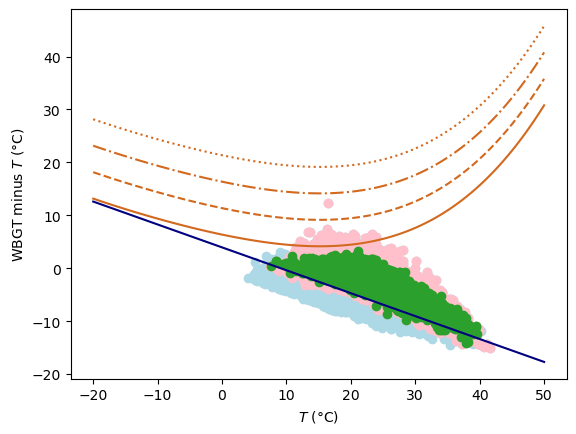

In [48]:
# Plot temperature (x-axis) vs. WBGT minus temperature (y-axis)
# Green region is where wind and radiation conditions meet assumptions for sWBGT (roughly) - green values should lie within (or very close to) upper and lower limits (solid curves)
# Assumptions have been made as to what values constitutes "light wind" and "moderate radiation"

low_rad_colour = 'lightblue'
not_light_wind_colour = 'pink'
set_main_colour = 'mediumorchid'
fourth_colour = 'tab:green'

if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
    plt.scatter(t_computed,wbgt_t_diff,c=low_rad_colour) # Plot all values
    plt.scatter(t_computed*low_rad_mask,wbgt_t_diff,c=not_light_wind_colour) # Plot all values excecpt those with low radiation (pink)
    plt.scatter(t_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,c=fourth_colour) # Plot all values except those with low radiation and high or low wind speeds (green)

    # Plot upper and lower limits from sWBGT-T relationship
    plt.plot(xp1, wbgt_t_min_limit(xp1,buffer=0),c='navy',linestyle='-')
    plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=0),c='chocolate',linestyle='-')
    
    # Upper limit plus 5
    plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=5),c='chocolate',linestyle='--')

    # Upper limit plus 10
    plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=10),c='chocolate',linestyle='-.')

    # Upper limit plus 15
    plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=15),c='chocolate',linestyle=':')
    
    plt.xlabel(t_label)
    plt.ylabel('WBGT minus $\it{T}$ (\N{degree sign}C)')


In [49]:
# Specify part of output filename
fname_out_common = '_month-' + set_month
fname_out_common += '_pt' + str(specify_point)


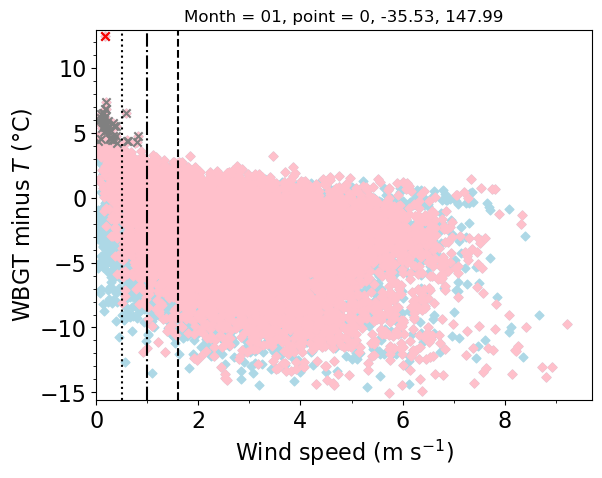

In [50]:
# Plot windspeed (x-axis) vs WBGT minus temperature (y-axis)
# Vertical lines show various wind speeds
# 'x' markers show large WBGT-T values 

set_fontsize = 16
set_msize = 20
set_marker_shape = 'D'


plt.rcParams.update({'font.size': 10,
                    'axes.labelsize':set_fontsize, # Axes labels
                    'xtick.labelsize':set_fontsize,
                    'ytick.labelsize':set_fontsize})


ax1 = plt.subplot(111)

plt.scatter(wind_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
    plt.scatter(wind_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)

plt.scatter(wind_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
plt.scatter(wind_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
plt.scatter(wind_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')

plt.plot([light_wind_min,light_wind_min],[np.nanmin(wbgt_t_diff)-0.5,np.nanmax(wbgt_t_diff)+0.5],c='k',linestyle='--') # Plot vertical line at 'light' wind limit
plt.plot([1.0,1.0],[np.nanmin(wbgt_t_diff)-0.5,np.nanmax(wbgt_t_diff)+0.5],c='k',linestyle='-.') # Plot vertical line at wind = 1 m/s
plt.plot([0.5,0.5],[np.nanmin(wbgt_t_diff)-0.5,np.nanmax(wbgt_t_diff)+0.5],c='k',linestyle=':') # Plot vertical line at wind = 0.5 m/s

plt.xlabel(wind_label)
plt.ylabel('WBGT minus $\it{T}$ (\N{degree sign}C)')

plt.xlim([0,np.nanmax(wind_computed)+0.5])
plt.ylim([np.nanmin(wbgt_t_diff)-0.5,np.nanmax(wbgt_t_diff)+0.5])

ax1.xaxis.set_major_locator(MultipleLocator(2)) # Major ticks
ax1.xaxis.set_minor_locator(MultipleLocator(1)) # Minor ticks
ax1.yaxis.set_major_locator(MultipleLocator(5)) # Major ticks
ax1.yaxis.set_minor_locator(MultipleLocator(1)) # Minor ticks

plt.title('Month = ' + set_month + ', point = ' + str(specify_point) + ', ' + str(lat_lat) + ', ' + str(lon_lon))

if specify_test == 'above_curve_magnitude_t':
    if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
        fname_out = dir_out + 'scatter_wind_vs_wbgt-t-diff_buffer' + fname_out_common + '_' + text_fname_in[0:-3]
        plt.savefig(fname_out + '.png', bbox_inches='tight', pad_inches=0.2, dpi=600)


Text(0.5, 1.0, 'Month = 01, specify_point = 0')

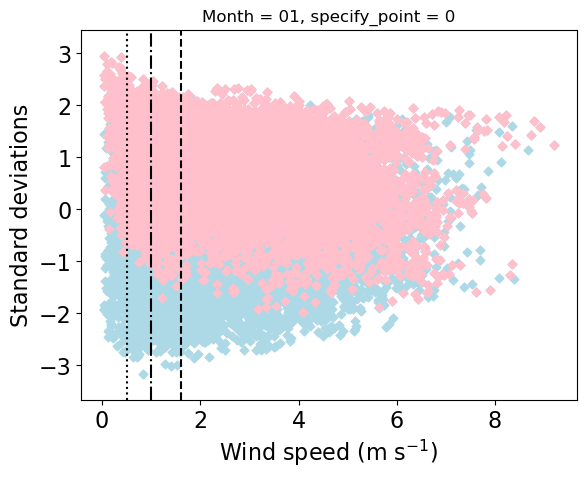

In [51]:
# Plot windspeed (x-axis) vs WBGT standard deviations (y-axis)
# This figure is not included in the report

plt.scatter(wind_computed,wbgt_computed_stds,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
    plt.scatter(wind_computed*low_rad_mask,wbgt_computed_stds,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)

plt.plot([light_wind_min,light_wind_min],[np.nanmin(wbgt_computed_stds)-0.5,np.nanmax(wbgt_computed_stds)+0.5],c='k',linestyle='--')
plt.plot([1.0,1.0],[np.nanmin(wbgt_computed_stds)-0.5,np.nanmax(wbgt_computed_stds)+0.5],c='k',linestyle='-.')
plt.plot([0.5,0.5],[np.nanmin(wbgt_computed_stds)-0.5,np.nanmax(wbgt_computed_stds)+0.5],c='k',linestyle=':')

plt.xlabel(wind_label)
plt.ylabel('Standard deviations')

plt.ylim([np.nanmin(wbgt_computed_stds)-0.5,np.nanmax(wbgt_computed_stds)+0.5])

plt.title('Month = ' + set_month + ', specify_point = ' + str(specify_point))


Text(0.5, 1.0, 'Month = 01, specify_point = 0')

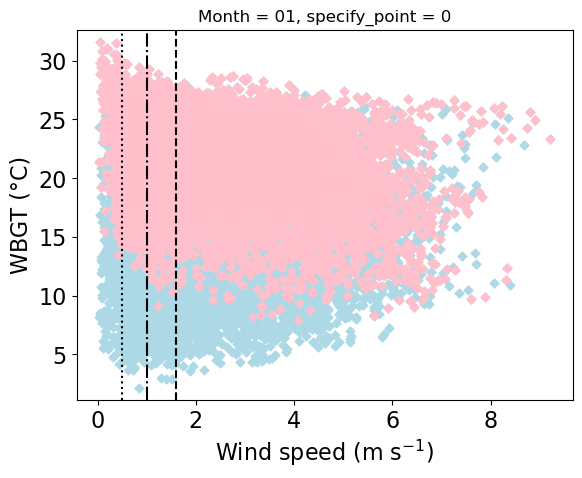

In [52]:
# Plot windspeed (x-axis) vs WBGT (y-axis)
# This figure is not included in the report

plt.scatter(wind_computed,wbgt_computed,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
    plt.scatter(wind_computed*low_rad_mask,wbgt_computed,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)

plt.plot([light_wind_min,light_wind_min],[np.nanmin(wbgt_computed)-1,np.nanmax(wbgt_computed)+1],c='k',linestyle='--')
plt.plot([1.0,1.0],[np.nanmin(wbgt_computed)-1,np.nanmax(wbgt_computed)+1],c='k',linestyle='-.')
plt.plot([0.5,0.5],[np.nanmin(wbgt_computed)-1,np.nanmax(wbgt_computed)+1],c='k',linestyle=':')

plt.xlabel(wind_label)
plt.ylabel('WBGT (\N{degree sign}C)')

plt.ylim([np.nanmin(wbgt_computed)-1,np.nanmax(wbgt_computed)+1])

plt.title('Month = ' + set_month + ', specify_point = ' + str(specify_point))


In [53]:
# If radiation data are not being used, create ones mask so the following figure can still be plotted
if (examine_radiation == 'no') and (examine_radiation_rsds == 'no'):
    low_rad_mask = np.ones(np.shape(wbgt_computed.data))

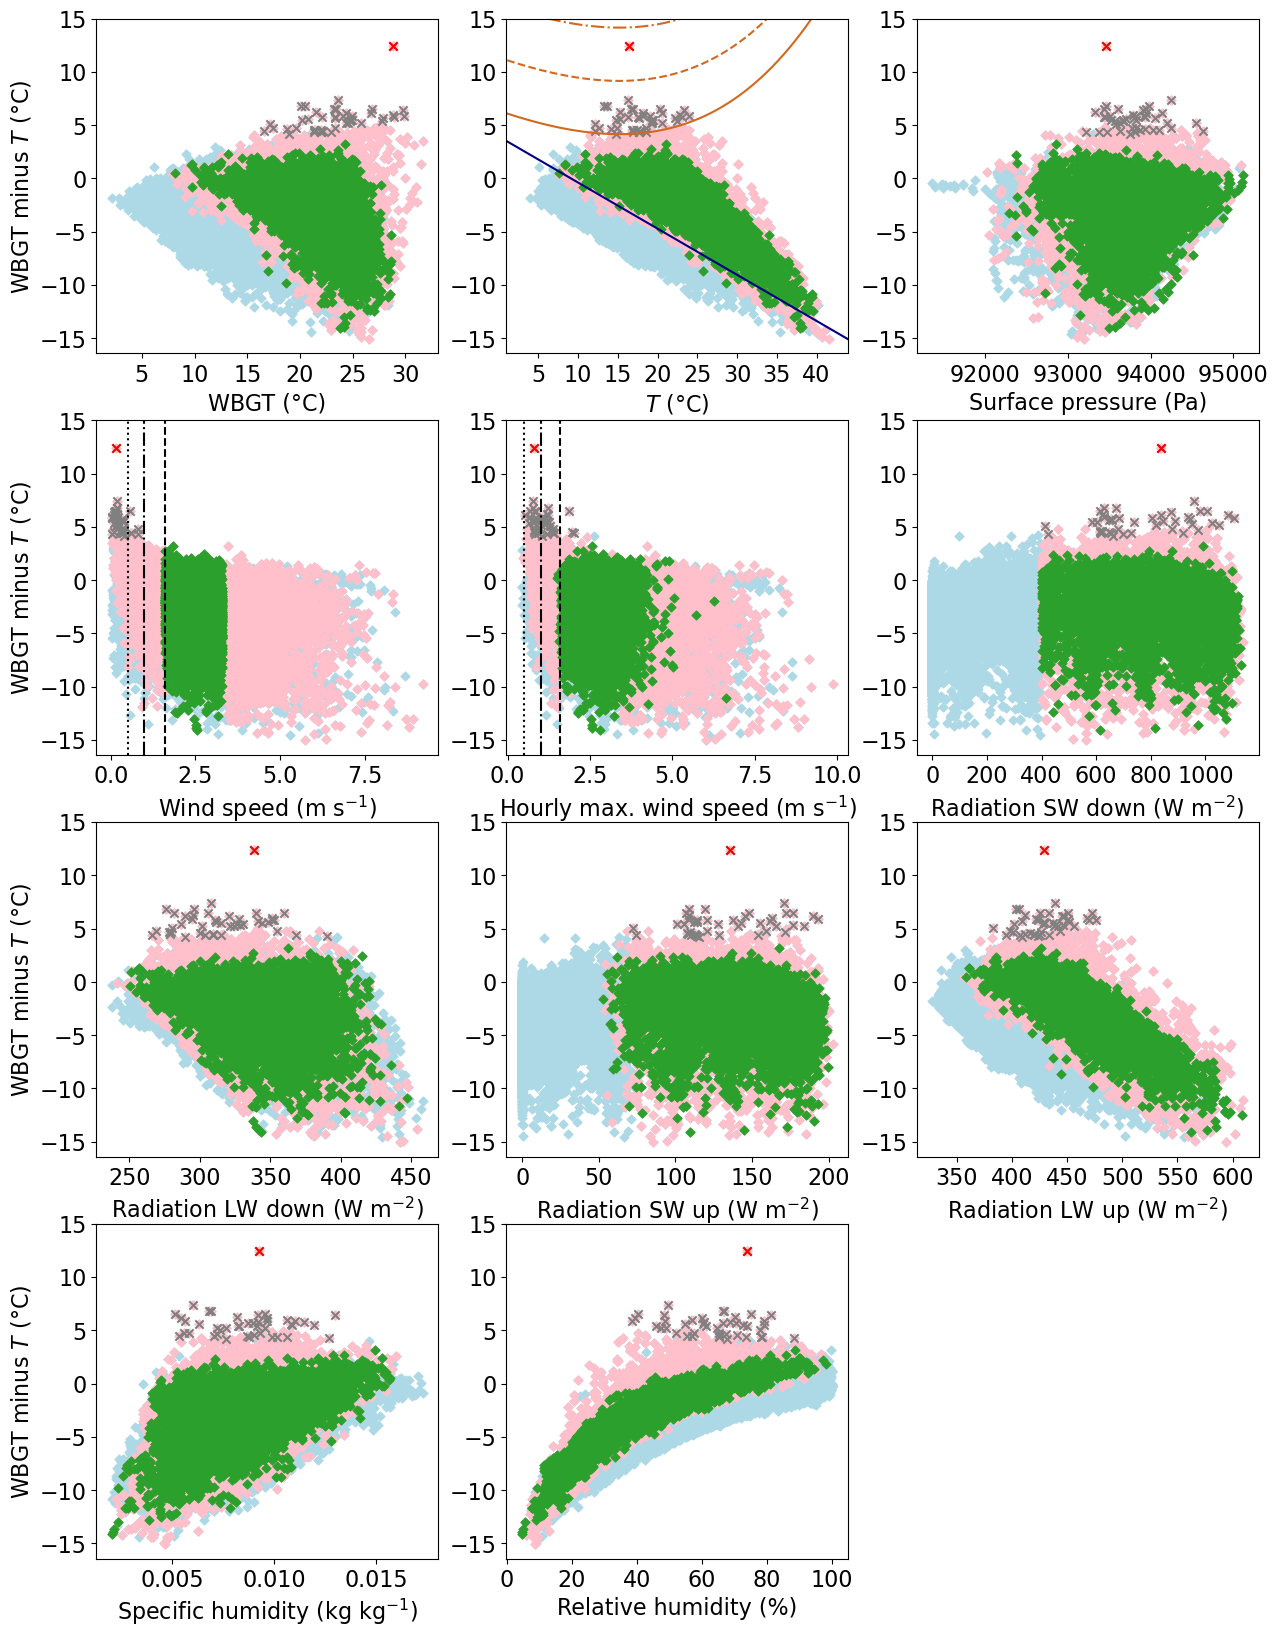

In [54]:
# Plot WBGT-T against all variables to see which are related to high WBGT-T differences
# This figure is not included in the report

fig, ax = plt.subplots(4, 3, figsize=(15,20))

set_msize = 20
set_x_msize = 50
set_marker_shape = 'D'


# WBGT
ax1 = plt.subplot(4,3,1)
p1a = plt.scatter(wbgt_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
p1a = plt.scatter(wbgt_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
plt.scatter(wbgt_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)

plt.scatter(wbgt_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
plt.scatter(wbgt_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
plt.scatter(wbgt_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')

plt.xlabel(wbgt_label)
plt.ylabel('WBGT minus $\it{T}$ (\N{degree sign}C)')
ax1.xaxis.set_major_locator(MultipleLocator(5)) # Major ticks

set_ymin = np.nanmin(ax1.get_ylim())
set_ymax = np.nanmax(ax1.get_ylim())
if set_ymax < 15:
    set_ymax = 15
    plt.ylim([set_ymin, set_ymax])



# T
ax3 = plt.subplot(4,3,2)
plt.scatter(t_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
plt.scatter(t_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
plt.scatter(t_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)

plt.scatter(t_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
plt.scatter(t_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
plt.scatter(t_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')

plt.plot(xp1, wbgt_t_min_limit(xp1,buffer=0),c='navy',linestyle='-')
plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=0),c='chocolate',linestyle='-')

plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=5),c='chocolate',linestyle='--')
plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=10),c='chocolate',linestyle='-.')
plt.plot(xp1, wbgt_t_max_limit(xp1,buffer=15),c='chocolate',linestyle=':')

plt.xlabel(t_label)
plt.xlim([np.floor(np.nanmin(t_computed))-2,np.ceil(np.nanmax(t_computed))+2])
plt.ylim([set_ymin, set_ymax])
ax3.xaxis.set_major_locator(MultipleLocator(5)) # Major ticks


# ps
if examine_pressure == 'yes':
    ax5 = plt.subplot(4,3,3)
    plt.scatter(p_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
    plt.scatter(p_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
    plt.scatter(p_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)
    
    plt.scatter(p_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
    plt.scatter(p_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
    plt.scatter(p_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')
    
    plt.xlabel(p_label)
    ax5.xaxis.set_major_locator(MultipleLocator(1000))
    plt.ylim([set_ymin, set_ymax])
    


# wind2m
ax6 = plt.subplot(4,3,4)
plt.scatter(wind_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
plt.scatter(wind_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
plt.scatter(wind_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)

plt.scatter(wind_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
plt.scatter(wind_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
plt.scatter(wind_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')

plt.plot([light_wind_min,light_wind_min],[set_ymin,set_ymax],c='k',linestyle='--')
plt.plot([1.0,1.0],[set_ymin,set_ymax],c='k',linestyle='-.')
plt.plot([0.5,0.5],[set_ymin,set_ymax],c='k',linestyle=':')

plt.xlabel(wind_label)
plt.ylabel('WBGT minus $\it{T}$ (\N{degree sign}C)')
plt.ylim([set_ymin, set_ymax])



# windmax
if examine_windmax == 'yes':
    ax4 = plt.subplot(4,3,5)
    plt.scatter(windmax_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
    plt.scatter(windmax_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
    plt.scatter(windmax_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)
    
    plt.scatter(windmax_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
    plt.scatter(windmax_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
    plt.scatter(windmax_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')
    
    plt.plot([light_wind_min,light_wind_min],[set_ymin,set_ymax],c='k',linestyle='--')
    plt.plot([1.0,1.0],[set_ymin,set_ymax],c='k',linestyle='-.')
    plt.plot([0.5,0.5],[set_ymin,set_ymax],c='k',linestyle=':')

    
    if windmax_label == 'Hourly maximum wind speed (m s$^{-1}$)':
        plt.xlabel('Hourly max. wind speed (m s$^{-1}$)')
    else:
        plt.xlabel(windmax_label)
    plt.ylim([set_ymin, set_ymax])




# rsds
if (examine_radiation == 'yes') or (examine_radiation_rsds == 'yes'):
    ax8 = plt.subplot(4,3,6)
    plt.scatter(rsds_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
    plt.scatter(rsds_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
    plt.scatter(rsds_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)

    plt.scatter(rsds_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
    plt.scatter(rsds_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
    plt.scatter(rsds_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')

    plt.xlabel(rsds_label)
    plt.ylim([set_ymin, set_ymax])
    ax8.xaxis.set_major_locator(MultipleLocator(200)) # Major ticks



# rlds
if examine_radiation == 'yes':
    ax9 = plt.subplot(4,3,7)
    plt.scatter(rlds_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
    plt.scatter(rlds_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
    plt.scatter(rlds_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)

    plt.scatter(rlds_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
    plt.scatter(rlds_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
    plt.scatter(rlds_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')

    plt.xlabel(rlds_label)
    plt.ylabel('WBGT minus $\it{T}$ (\N{degree sign}C)')
    plt.ylim([set_ymin, set_ymax])
    ax9.xaxis.set_major_locator(MultipleLocator(50)) # Major ticks



# rsus
if examine_radiation == 'yes':
    ax10 = plt.subplot(4,3,8)
    plt.scatter(rsus_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
    plt.scatter(rsus_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
    plt.scatter(rsus_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)

    plt.scatter(rsus_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
    plt.scatter(rsus_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
    plt.scatter(rsus_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')
    
    plt.xlabel(rsus_label)
    plt.ylim([set_ymin, set_ymax])
    ax10.xaxis.set_major_locator(MultipleLocator(50)) # Major ticks



# rlus
if examine_radiation == 'yes':
    ax11 = plt.subplot(4,3,9)
    plt.scatter(rlus_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
    plt.scatter(rlus_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
    plt.scatter(rlus_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)
    
    plt.scatter(rlus_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
    plt.scatter(rlus_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
    plt.scatter(rlus_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')
    
    plt.xlabel(rlus_label)
    plt.ylim([set_ymin, set_ymax])
    ax11.xaxis.set_major_locator(MultipleLocator(50)) # Major ticks




# huss
if examine_humidity == 'yes':
    ax13 = plt.subplot(4,3,10)
    plt.scatter(huss_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
    plt.scatter(huss_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
    plt.scatter(huss_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)
    
    plt.scatter(huss_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
    plt.scatter(huss_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
    plt.scatter(huss_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')
    
    plt.xlabel(huss_label)
    plt.ylabel('WBGT minus $\it{T}$ (\N{degree sign}C)')
    plt.ylim([set_ymin, set_ymax])



# hurs
if examine_humidity == 'yes':
    ax14 = plt.subplot(4,3,11)
    plt.scatter(hurs_computed,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=low_rad_colour)
    plt.scatter(hurs_computed*low_rad_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=not_light_wind_colour)
    plt.scatter(hurs_computed*low_rad_mask*high_wind_mask*low_wind_mask,wbgt_t_diff,s=set_msize,marker=set_marker_shape,c=fourth_colour)
    
    plt.scatter(hurs_computed,wbgt_t_diff*above_curve_t_b0,marker='x',c='grey')
    plt.scatter(hurs_computed,wbgt_t_diff*above_curve_t_b5,marker='x',c='r')
    plt.scatter(hurs_computed,wbgt_t_diff*above_curve_t_b10,marker='x',c='darkred')
    
    plt.xlabel(hurs_label)
    plt.ylim([set_ymin, set_ymax])
    ax14.xaxis.set_major_locator(MultipleLocator(20)) # Major ticks


ax20 = plt.subplot(4,3,12)
ax20.set_axis_off()

